In [1]:
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import glob
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Create Model Registry

In [ ]:
def rgb_to_hex(r, g, b):
    return f"#{r:02x}{g:02x}{b:02x}"

MODEL_REGISTRY = {
    "WaveletFlow_1scale_db2_v4.0": dict(
        label  = "WFM 1-scale (ours)",
        #color  = rgb_to_hex(55, 82, 64),
        color  = rgb_to_hex(98, 124, 107),
        dash   = (1, 0),
        lw     = 2.5,                    # ours: thicker
        groups = {"ours", "generative"},
        legend_rank = 0,
    ),
    "WaveletFlow_3scales_db2_v4.0": dict(
        label  = "WFM 3-scales (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0),
        lw     = 2.5,                    # ours: thicker
        groups = {"ours", "generative"},
        legend_rank = 1,
    ),
    "FM_data_space_v4.0": dict(
        label  = r"FM$_{pixel}$",
        color  = rgb_to_hex(176, 176, 176),
        dash   = (1, 0),
        lw     = 1.8,
        groups = {"generative"},
        legend_rank = -1,
    ),
    "FourierFlow_32modes_v4.0": dict(
        label  = r"FM$_{fourier}$",
        color  = rgb_to_hex(143, 94, 106),
        dash   = (1, 0),
        lw     = 1.8,
        groups = {"generative"},
        legend_rank = 3,
    ),
    "WDNO": dict(
        label  = "WDNO",
        color  = rgb_to_hex(191, 134, 148),
        dash   = (1, 0),
        lw     = 1.8,
        groups = {"generative"},
        legend_rank = 4,
    ),
    "WNO_3scales_db2": dict(
        label  = "WNO",
        color  = rgb_to_hex(176, 136, 84),
        #color  = rgb_to_hex(145, 74, 38),
        dash   = (1, 0),
        lw     = 1.8,
        groups = {"deterministic"},
        legend_rank = 5,
    ),
    "FNO": dict(
        label  = "FNO",
        #color  = rgb_to_hex(205, 170, 85),
        color  = rgb_to_hex(208, 169, 110),
        dash   = (1, 0),
        lw     = 1.8,
        groups = {"deterministic"},
        legend_rank = 6,
    ),
    "TFNO": dict(
        label  = "TFNO",
        #color  = rgb_to_hex(207, 185, 122),
        color  = rgb_to_hex(236, 227, 163),
        dash   = (1, 0),
        lw     = 1.8,
        groups = {"deterministic"},
        legend_rank = 7,
    ),
}

PDEs = ['turbulent_radiative_layer_2D', 'rayleigh_benard', 'active_matter']

model_checklist = [m for m in MODEL_REGISTRY]

palette     = {m: MODEL_REGISTRY[m]["color"] for m in model_checklist}
dashes      = {m: MODEL_REGISTRY[m]["dash"]  for m in model_checklist}
labels      = {m: MODEL_REGISTRY[m]["label"] for m in model_checklist}
linewidths  = {m: MODEL_REGISTRY[m]["lw"]    for m in model_checklist}

det_models  = [m for m in model_checklist if "deterministic" in MODEL_REGISTRY[m]["groups"]]
gen_models  = [m for m in model_checklist if "generative" in MODEL_REGISTRY[m]["groups"]]
ours_models = [m for m in model_checklist if "ours"       in MODEL_REGISTRY[m]["groups"]]

color_to_model = {v: k for k, v in palette.items()}

GT_LABEL             = "Ground-truth"
palette[GT_LABEL]    = "#222222"
dashes[GT_LABEL]     = (1, 0)
labels[GT_LABEL]     = "Ground-truth"
linewidths[GT_LABEL] = 1.8    

# Load stats files

In [3]:
GT_LABEL = "Ground-truth"
LOAD_STATS = True
LOAD_PSD   = False

def enrich(df, stem, model_name, dataset_name):
    """Add metadata columns, preserving GT rows already labelled in the CSV."""
    parts     = stem.split('_')
    nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
    nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)
    if 'model' in df.columns:
        df.loc[df['model'] != GT_LABEL, 'model'] = model_name
    else:
        df['model'] = model_name
    df['source']    = stem
    df['dataset']   = dataset_name
    df['pde']       = dataset_name          # ← new: explicit PDE tag
    df['nsampling'] = int(nsampling) if nsampling else None
    df['nens']      = int(nens)      if nens      else None
    return df

dfs_stats, dfs_psd = [], []

for pde in PDEs:
    print(f"\n{'='*60}\nLoading PDE: {pde}\n{'='*60}")
    for model in model_checklist:
        pattern_stats = f'{PROJECT_ROOT}/experiments/{pde}/metrics/{model}*stats.csv'
        pattern_psd   = f'{PROJECT_ROOT}/experiments/{pde}/metrics/{model}*psd.csv'
        matched_files_stats = glob.glob(pattern_stats) if LOAD_STATS else []
        matched_files_psd   = glob.glob(pattern_psd) if LOAD_PSD else []

        if not matched_files_stats:
            print(f"  [WARN] No stats files for model '{model}' | pde '{pde}'")
        if not matched_files_psd:
            print(f"  [WARN] No psd   files for model '{model}' | pde '{pde}'")

        for fpath in sorted(matched_files_stats):
            try:
                df   = pd.read_csv(fpath)
                stem = Path(fpath).stem
                df   = enrich(df, stem, model, pde)
                dfs_stats.append(df)
                print(f"  [OK stats] {df.shape} | {Path(fpath).name:70s}")
            except Exception as e:
                print(f"  [ERR] {fpath}: {e}")

        for fpath in sorted(matched_files_psd):
            try:
                df   = pd.read_csv(fpath)
                stem = Path(fpath).stem
                df   = enrich(df, stem, model, pde)
                dfs_psd.append(df)
                print(f"  [OK psd  ] {df.shape} | {Path(fpath).name:70s}")
            except Exception as e:
                print(f"  [ERR] {fpath}: {e}")

# ── Concat & deduplicate ───────────────────────────────────────────────────────
DEDUP_EXCLUDE = {'source', 'nsampling', 'nens'}

if dfs_stats:
    stats_df = pd.concat(dfs_stats, ignore_index=True)
    stats_df = stats_df.drop_duplicates(
        subset=[c for c in stats_df.columns if c not in DEDUP_EXCLUDE]
    )
    print(f"\nstats_df: {stats_df.shape}  |  columns: {list(stats_df.columns)}")
else:
    stats_df = pd.DataFrame()
    print("[WARN] No data loaded — stats_df is empty.")

if dfs_psd:
    psd_df = pd.concat(dfs_psd, ignore_index=True)
    psd_df = psd_df.drop_duplicates(
        subset=[c for c in psd_df.columns if c not in DEDUP_EXCLUDE]
    )
    print(f"\npsd_df:   {psd_df.shape}  |  columns: {list(psd_df.columns)}")
else:
    psd_df = pd.DataFrame()
    print("[WARN] No data loaded — psd_df is empty.")


Loading PDE: turbulent_radiative_layer_2D
  [WARN] No psd   files for model 'WaveletFlow_1scale_db2_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'WaveletFlow_3scales_db4_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WaveletFlow_3scales_db4_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'FM_data_space_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | FM_data_space_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'FourierFlow_32modes_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 35) | FourierFlow_32modes_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'WDNO' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WDNO_1scale_db2_turbulent_r

# Config: Plot axes limits and aesthetichs

In [4]:
PDE_LABELS = {
    'turbulent_radiative_layer_2D' : 'Turbulent Radiative Layer 2D',
    'rayleigh_benard'              : 'Rayleigh-Bénard',
    'active_matter'                : 'Active Matter',
    }

# x-axis limits for PDE
pde_xlims = {
    'turbulent_radiative_layer_2D' : (-5, 100),
    'rayleigh_benard'              : (-5, 200),
    'active_matter'                : (-5, 80),
    }

band_ylims = {
    "Low"   : (-0.01, 0.5), 
    "Mid"   : (-0.01, 0.5), 
    "High"  : (-0.01, 0.5)
    }

bands = ["Low", "Mid", "High"]

LEGEND_LW  = 1.8
TEXT_WIDTH = 14    # inches
ROW_HEIGHT = 2.8   # inches per band row

## Helpers

## Compute horizon and "model_type" attributes

In [5]:
aggregate_mode = "mean"

def horizon_rayleigh_benard(t):
    if t < 32:
        return "01:32"
    elif t < 64:
        return "33:64"
    else:
        return "65:196"

def horizon_active_matter(t):
    if t < 16:
        return "01:16"
    elif t < 32:
        return "17:32"
    else:
        return "33:77"
    
def horizon_turbulent_radiative_layer_2D(t):
    if t < 32:
        return "01:32"
    elif t < 64:
        return "33:64"
    else:
        return "65:97"

def aggregate(x):
    if "mean" in aggregate_mode:
        return np.nanmean(x)
    elif "median" in aggregate_mode:
        return np.nanmedian(x)

def model_type(model):
    groups = MODEL_REGISTRY.get(model, {}).get("groups", {})
    if "ours"       in groups: return "ours"
    if "generative" in groups: return "generative"
    return "deterministic"

# ── Horizon: write into matching rows only, don't overwrite the full column ───
horizon_fn = {
    'turbulent_radiative_layer_2D': horizon_turbulent_radiative_layer_2D,
    'rayleigh_benard':              horizon_rayleigh_benard,
    'active_matter':                horizon_active_matter,
}

if LOAD_STATS:
    stats_df['step'] = stats_df['step'] + 1

    field_names = stats_df['field'].unique()
    n_fields = len(field_names)

    stats_df["horizon"] = np.nan                         
    for pde, fn in horizon_fn.items():
        mask = stats_df["pde"] == pde
        stats_df.loc[mask, "horizon"] = stats_df.loc[mask, "step"].apply(fn)
    stats_df["model_type"] = stats_df["model"].apply(model_type)
    stats_df["spread_skill_new"] = (stats_df["spread"] + 1e-3) / (stats_df["rmse"] + 1e-3)

if LOAD_PSD:
    psd_df['step']   = psd_df['step'] + 1

    field_names = psd_df['field'].unique()
    n_fields = len(field_names)
    
    psd_df["horizon"] = np.nan                         
    for pde, fn in horizon_fn.items():
        mask = psd_df["pde"] == pde
        psd_df.loc[mask, "horizon"] = psd_df.loc[mask, "step"].apply(fn)
    psd_df["model_type"] = psd_df["model"].apply(model_type)

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_69085/3919345017.py:55: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['01:32' '01:32' '01:32' ... '65:97' '65:97' '65:97']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  stats_df.loc[mask, "horizon"] = stats_df.loc[mask, "step"].apply(fn)


## Bar plot helper

In [6]:
# ── Shared style config ───────────────────────────────────────────────────────
TEXT_WIDTH = 12.0
BAR_HEIGHT = 2.8
OVERFLOW_MARGIN = 0.92
HLINE_MODEL = "FM_data_space_v4.0"

hatch_lookup = {
    "ours":          "",
    "generative":    "",
    "deterministic": "",
}

edgecolor_lookup = {
    "ours":          None,
    "generative":    "white",
    "deterministic": "white",
}

det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

def get_edgecolor(mtype, model_name):
    ec = edgecolor_lookup.get(mtype)
    return ec if ec is not None else palette[model_name]

def legend_order(model_subset):
    registry_keys = list(MODEL_REGISTRY.keys())
    def rank(m):
        return (
            MODEL_REGISTRY[m].get("legend_rank", 999),  # explicit rank first
            registry_keys.index(m),                      # then insertion order
        )
    return sorted(model_subset, key=rank)

def make_bar_fig(
    stats_df,
    model_subset,
    metric_col,
    metric_label,
    pde_ylims,
    PDEs,
    PDE_LABELS,
    ncol_legend=4,
    legend_pos=(0.5, -0.15),
    xlabel = "Lead Time", 
):
    n_pdes    = len(PDEs)
    bar_models = [m for m in model_subset if m != HLINE_MODEL]
    bar_width  = 0.8 / len(bar_models)

    fig, axes = plt.subplots(
        1, n_pdes,
        figsize=(TEXT_WIDTH, BAR_HEIGHT),
        sharey=False,
    )

    for col, pde in enumerate(PDEs):
        ax    = axes[col]
        table = stats_df[
            (stats_df["pde"]   == pde) &
            (stats_df["model"].isin(model_subset))
        ]

        if all(b in bands for b in table["horizon"].dropna().unique()):
            horizons = [b for b in bands if b in table["horizon"].dropna().unique()]
        else:
            horizons = sorted(table["horizon"].dropna().unique(), key=lambda x: int(x.split(":")[0]))
                
        ymax = pde_ylims[pde][1]

        for h_idx, horizon in enumerate(horizons):
            h_table = table[table["horizon"] == horizon]

            # bars (all models except HLINE_MODEL)
            model_vals = (
                h_table[h_table["model"] != HLINE_MODEL]
                .groupby("model")[metric_col]
                .apply(aggregate)
                .reindex(bar_models)
                .dropna()
                .sort_values()
            )
            n_present = len(model_vals)
            offsets   = np.linspace(
                -(n_present - 1) / 2,
                 (n_present - 1) / 2,
                n_present,
            ) * bar_width

            non_overflow = model_vals[model_vals <= ymax * OVERFLOW_MARGIN]
            clip_to = non_overflow.max() * 1.05 if len(non_overflow) else ymax * OVERFLOW_MARGIN

            for offset, (model_name, val) in zip(offsets, model_vals.items()):
                mtype   = det_lookup.get(model_name, "ours")
                is_over = val > ymax * OVERFLOW_MARGIN
                clipped = clip_to if is_over else val
                ax.bar(
                    h_idx + offset, clipped,
                    width=bar_width,
                    color=palette[model_name],
                    hatch=hatch_lookup.get(mtype, ""),
                    edgecolor=get_edgecolor(mtype, model_name),
                    linewidth=0.4,
                )

            # ── horizontal line for HLINE_MODEL ──────────────────────────
            if HLINE_MODEL in h_table["model"].values:
                hline_val = aggregate(h_table[h_table["model"] == HLINE_MODEL][metric_col])
                if not np.isnan(hline_val):
                    hline_val = min(hline_val, ymax * OVERFLOW_MARGIN)
                    ax.hlines(
                        hline_val,
                        h_idx - 0.4, h_idx + 0.4,   # span the full horizon group
                        colors=palette[HLINE_MODEL],
                        linewidths=2.0,
                        linestyles="--",
                        zorder=5,
                    )

        ax.set_xticks(range(len(horizons)))
        ax.set_xticklabels(horizons, fontsize=12)
        #ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlabel(xlabel, fontsize=15)
        ax.set_ylim(*pde_ylims[pde])
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
        ax.set_ylabel(metric_label if col == 0 else "", fontsize=15)
        ax.tick_params(labelleft=True, labelsize=12)
        ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

    # ── Legend ────────────────────────────────────────────────────────────────
    ordered_models = legend_order(
        [m for m in model_subset if m in stats_df["model"].unique()]
    )

    legend_handles = []
    for m in ordered_models:
        if m == HLINE_MODEL:
            legend_handles.append(
                mlines.Line2D(
                    [], [],
                    color=palette[m], linewidth=2.0, linestyle="--",
                    label=labels.get(m, m),
                )
            )
        else:
            mtype = det_lookup.get(m, "ours")
            legend_handles.append(
                mpatches.Patch(
                    facecolor=palette[m],
                    hatch=hatch_lookup.get(mtype, ""),
                    edgecolor=get_edgecolor(mtype, m),
                    label=labels.get(m, m),
                    linewidth=0.4,
                )
            )

    fig.tight_layout(pad=0.8)
    fig.subplots_adjust(bottom=0.22, left=0.08, right=0.93)
    fig.legend(
        handles=legend_handles,
        loc="lower center", ncol=ncol_legend,
        bbox_to_anchor=legend_pos,
        frameon=True, fontsize=12,
    )
    return fig

# Figure 1 (bars): VRMSE and CRPS Bar Plot across rollout regimes

## Figure 1A (bars): VRMSE across deterministic baselines

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_69085/3919345017.py:29: RuntimeWarning: Mean of empty slice
  return np.nanmean(x)


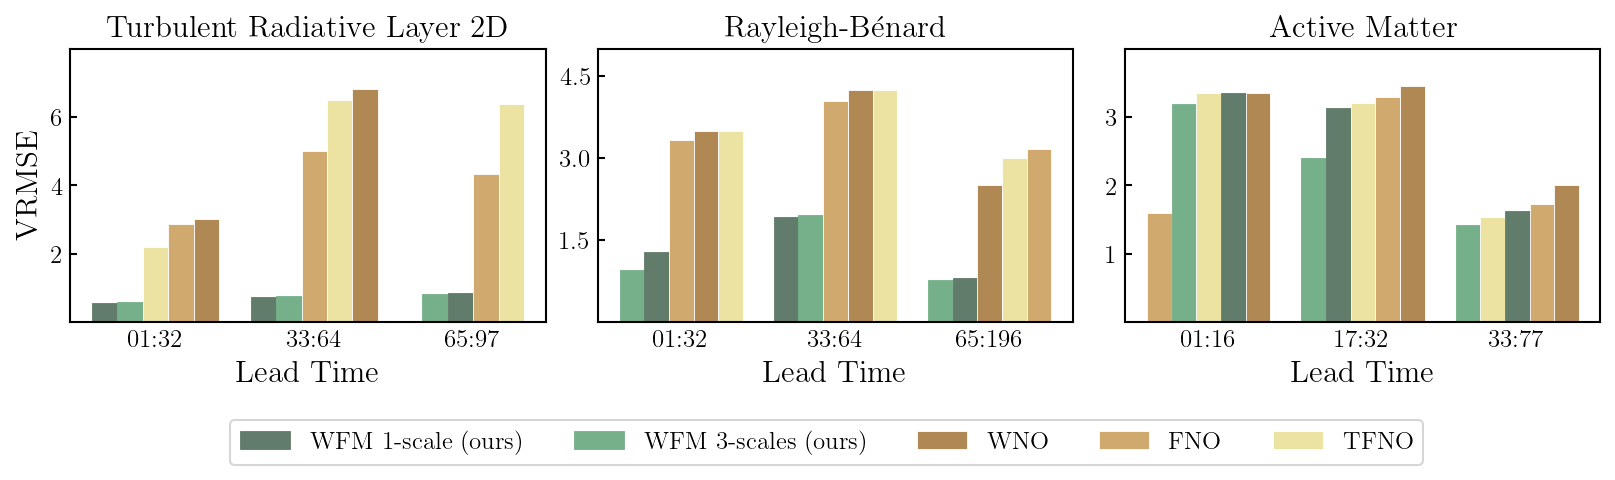

In [7]:
pde_bar_ylims_vrmse = {
    'turbulent_radiative_layer_2D': (0, 8.0),
    'rayleigh_benard':              (0, 5.0),
    'active_matter':                (0, 4.0),
}

# ── Figure A: VRMSE — deterministic models ────────────────────────────────────
fig_vrmse = make_bar_fig(
    stats_df,
    model_subset  = det_models + ours_models,
    metric_col    = "vrmse",
    metric_label  = "VRMSE",
    pde_ylims     = pde_bar_ylims_vrmse,
    PDEs          = PDEs,
    PDE_LABELS    = PDE_LABELS,
    ncol_legend   = 5,
    legend_pos    = (0.5, -0.15),
)
#fig_vrmse.savefig(f"{PROJECT_ROOT}/figures/fig1A_bar_vrmse_det.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

## Figure 1A-all (bars): VRMSE across deterministic and generative models

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_69085/3919345017.py:29: RuntimeWarning: Mean of empty slice
  return np.nanmean(x)


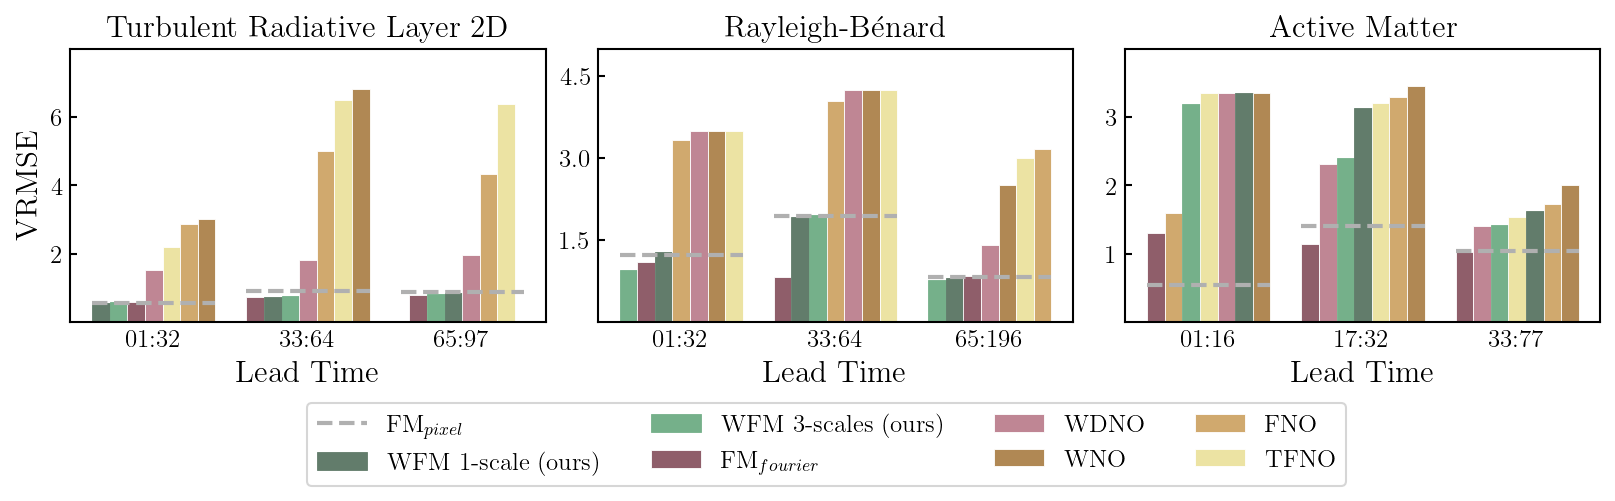

In [8]:
pde_bar_ylims_vrmse = {
    'turbulent_radiative_layer_2D': (0, 8.0),
    'rayleigh_benard':              (0, 5.0),
    'active_matter':                (0, 4.0),
}

# ── Figure A: VRMSE — all models ─────────────────────────────────────────────
fig_vrmse = make_bar_fig(
    stats_df,
    model_subset  = gen_models + det_models,
    metric_col    = "vrmse",
    metric_label  = "VRMSE",
    pde_ylims     = pde_bar_ylims_vrmse,
    PDEs          = PDEs,
    PDE_LABELS    = PDE_LABELS,
    ncol_legend   = 4,
    legend_pos    = (0.5, -0.2),
)
#fig_vrmse.savefig(f"{PROJECT_ROOT}/figures/fig1A_bar_vrmse_all.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

## Figure 1B (bars): CRPS across generative models

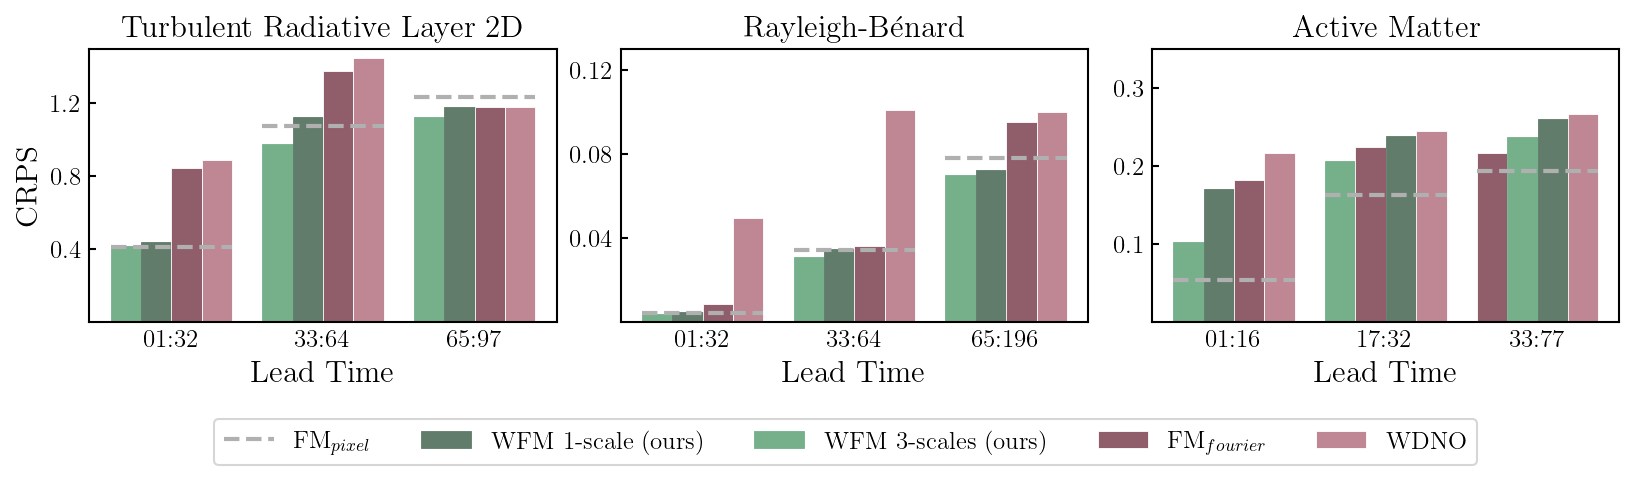

In [9]:
pde_bar_ylims_crps = {
    'turbulent_radiative_layer_2D': (0, 1.5),
    'rayleigh_benard':              (0, 0.13),
    'active_matter':                (0, 0.35),
}

# Figure B: CRPS across generative models
fig_crps = make_bar_fig(
    stats_df,
    model_subset  = gen_models,
    metric_col    = "crps",
    metric_label  = "CRPS",
    pde_ylims     = pde_bar_ylims_crps,
    PDEs          = PDEs,
    PDE_LABELS    = PDE_LABELS,
    ncol_legend   = 5,
)
#fig_crps.savefig(f"{PROJECT_ROOT}/figures/fig1B_bar_crps_gen.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

## Figure 1B-all (bars): CRPS across deterministic and generative models

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_69085/3919345017.py:29: RuntimeWarning: Mean of empty slice
  return np.nanmean(x)


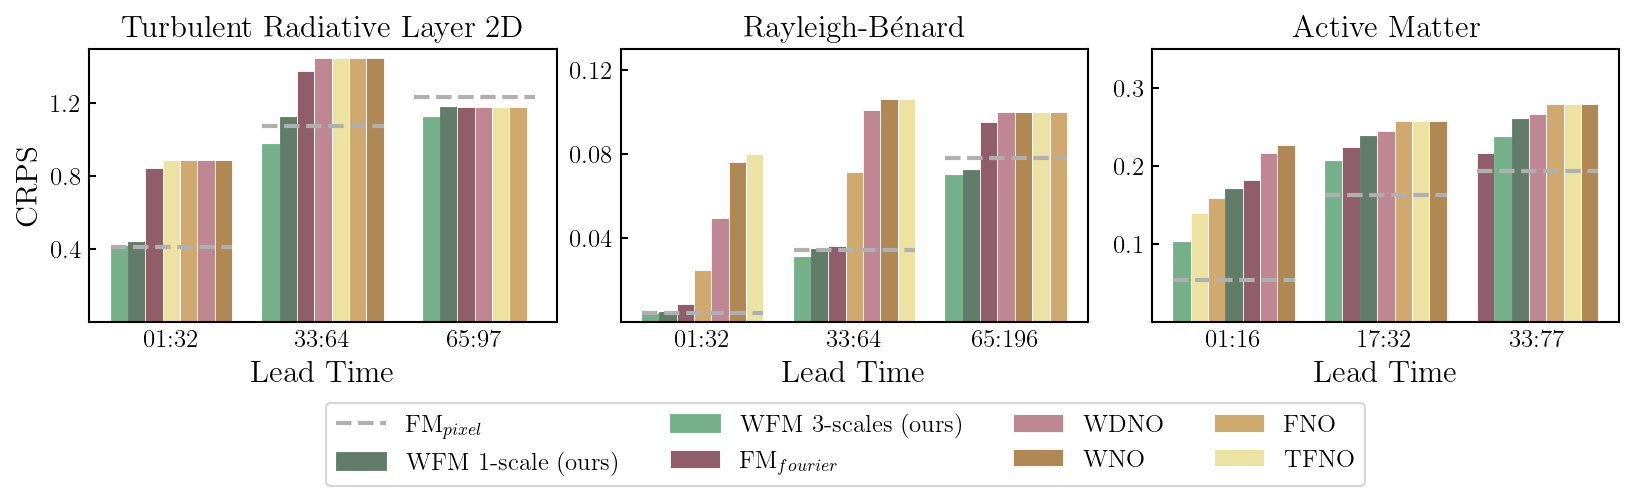

In [10]:
pde_bar_ylims_crps = {
    'turbulent_radiative_layer_2D': (0, 1.5),
    'rayleigh_benard':              (0, 0.13),
    'active_matter':                (0, 0.35),
}

# ── Figure B: CRPS — generative models ───────────────────────────────────────
fig_crps = make_bar_fig(
    stats_df,
    model_subset  = gen_models + det_models,
    metric_col    = "crps",
    metric_label  = "CRPS",
    pde_ylims     = pde_bar_ylims_crps,
    PDEs          = PDEs,
    PDE_LABELS    = PDE_LABELS,
    ncol_legend   = 4,
    legend_pos    =(0.5, -0.2)
)
#fig_crps.savefig(f"{PROJECT_ROOT}/figures/fig1B_bar_crps_all.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure 2 (bars): Spectral Coherence RMSE 

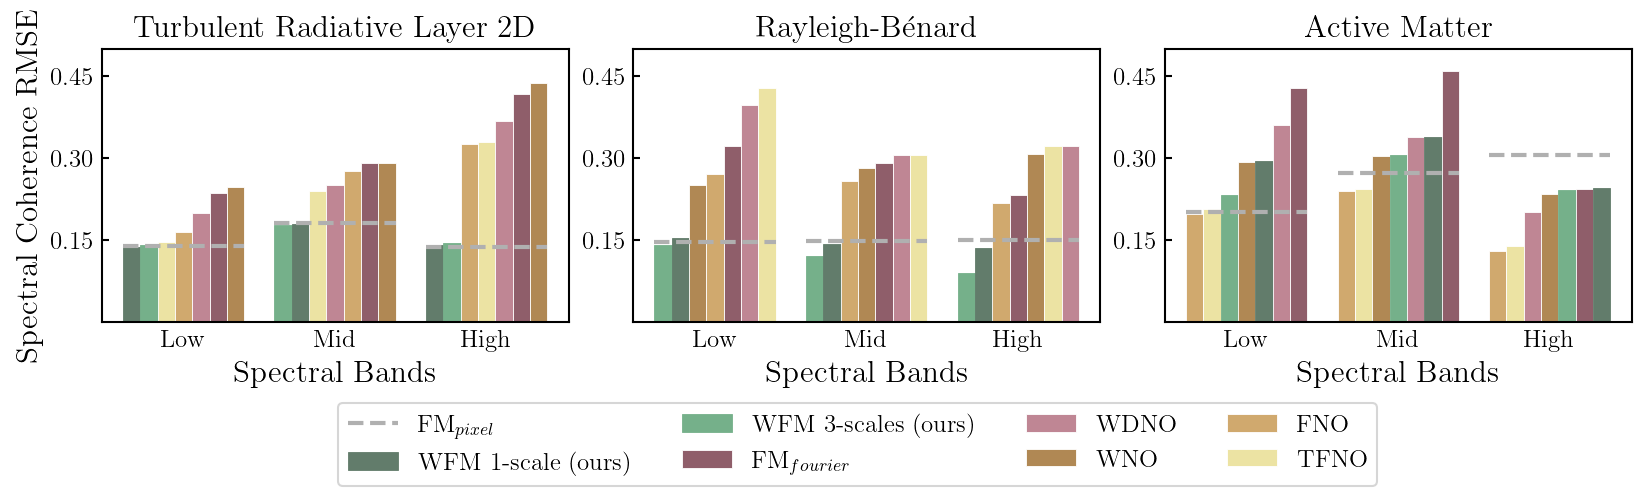

In [11]:
band_cols = {"rmse_c_low": "Low", "rmse_c_mid": "Mid", "rmse_c_high": "High"}

# Melt bands into a long "horizon" column so make_bar_fig works unchanged
stats_df_bands = (
    stats_df
    .melt(
        id_vars=[c for c in stats_df.columns if c not in band_cols],
        value_vars=list(band_cols.keys()),
        var_name="band_col",
        value_name="rmse_band",
    )
    .assign(horizon=lambda df: df["band_col"].map(band_cols))  # "Low"/"Mid"/"High"
    .drop(columns="band_col")
)

# Monkey-patch sorted call by pre-sorting horizons externally — done via category dtype
stats_df_bands["horizon"] = pd.Categorical(
    stats_df_bands["horizon"], categories=["Low", "Mid", "High"], ordered=True
)

pde_bar_ylims_vrmse_bands = {
    'turbulent_radiative_layer_2D': (0, 0.50),
    'rayleigh_benard':              (0, 0.50),
    'active_matter':                (0, 0.50),
}

fig_sc_rmse_bands = make_bar_fig(
    stats_df_bands,
    model_subset  = gen_models + det_models,
    metric_col    = "rmse_band",
    metric_label  = "Spectral Coherence RMSE",
    pde_ylims     = pde_bar_ylims_vrmse_bands,
    PDEs          = PDEs,
    PDE_LABELS    = PDE_LABELS,
    ncol_legend   = 4,
    legend_pos    = (0.5, -0.2),
    xlabel        = "Spectral Bands",
)
#fig_sc_rmse_bands.savefig(f"{PROJECT_ROOT}/figures/fig2_sc_rmse_bands.pdf", dpi=400, bbox_inches="tight", transparent=False)

# APPENDIX Figure: Spectral Coherence RMSE 

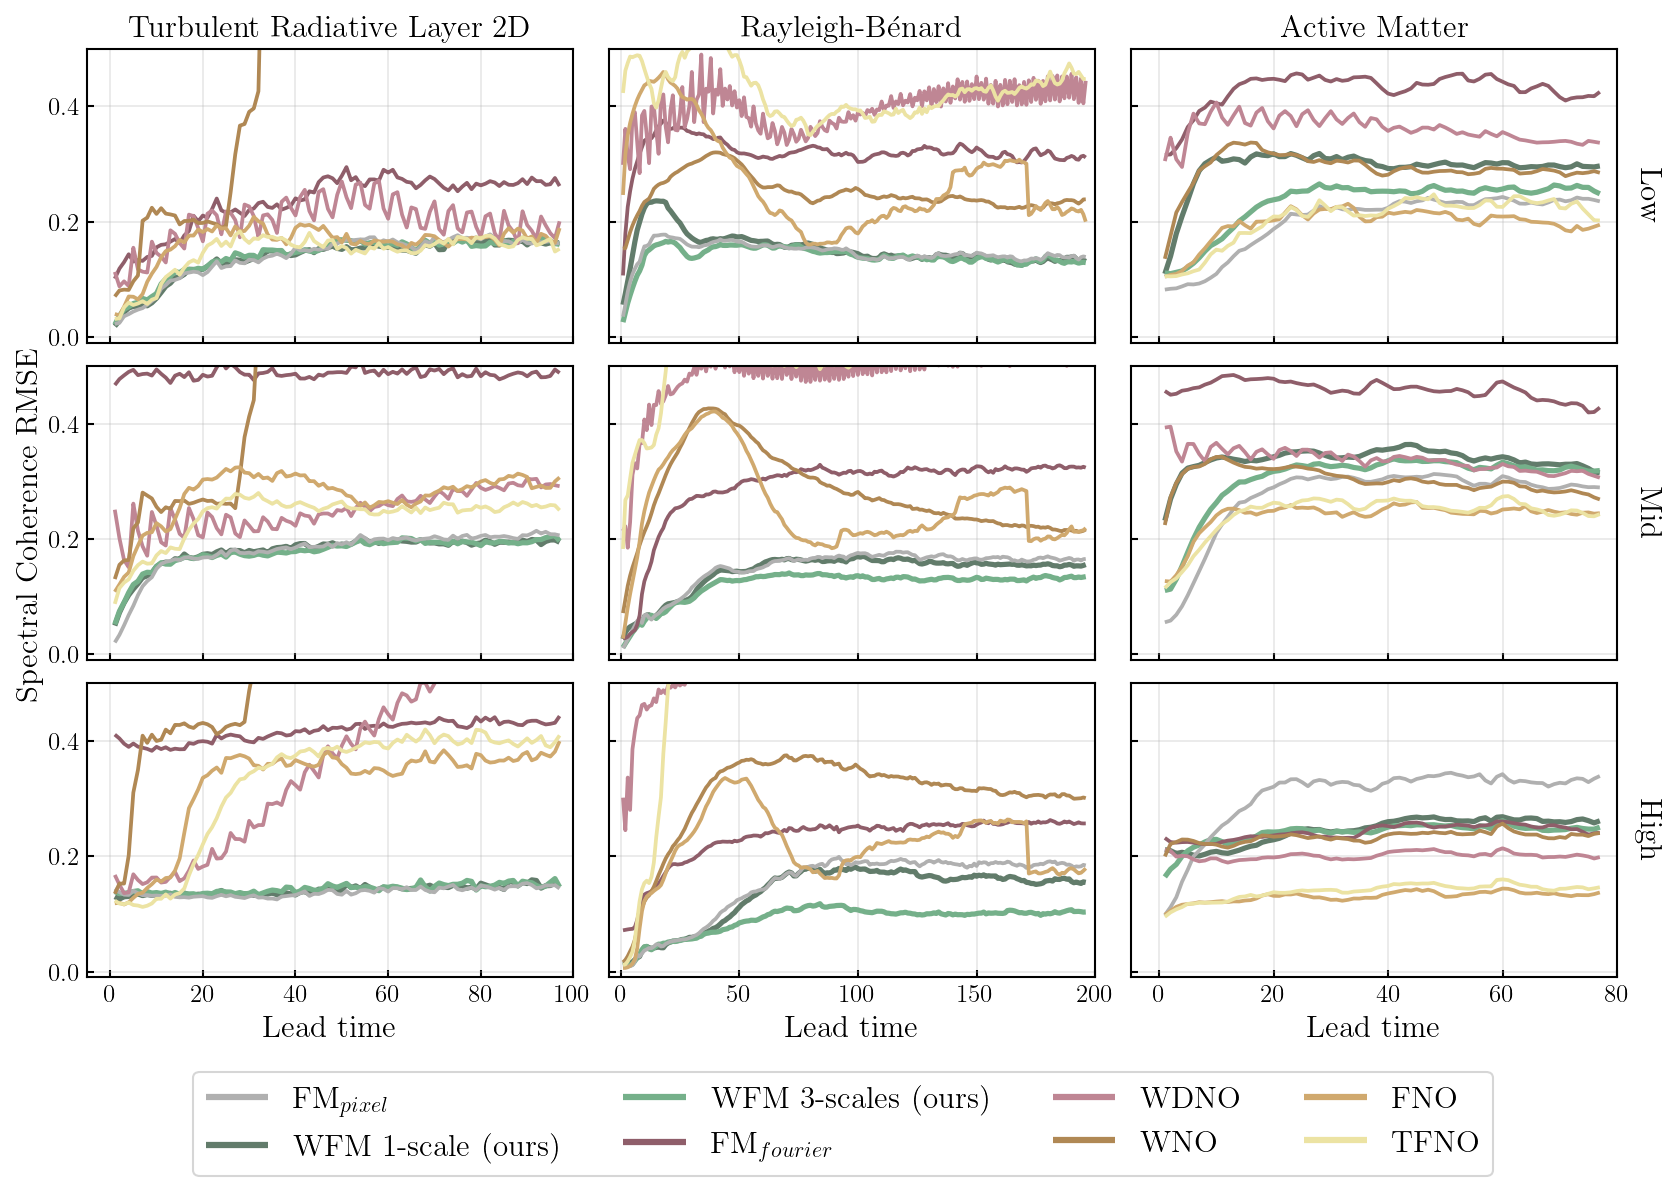

In [12]:
n_pdes, n_bands = len(PDEs), len(bands)
fig1, axs1 = plt.subplots(
    n_bands, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_bands),
    sharex="col",
    sharey="row",
)

raw_h, raw_l = None, None

for col, pde in enumerate(PDEs):
    table = stats_df[(stats_df["pde"] == pde) & (stats_df["model"].isin(det_models + gen_models))]
    for row, band in enumerate(bands):
        ax = axs1[row, col]
        sns.lineplot(
            table, x="step",
            y=f"rmse_c_{band.lower()}",
            hue="model", style="model",
            dashes=dashes,
            estimator=aggregate, errorbar=None,
            palette=palette, ax=ax, linewidth=1.0,
            alpha=1.0,
        )

        for line in ax.get_lines():
            hex_color = mcolors.to_hex(line.get_color())
            model = color_to_model.get(hex_color)
            if model and model in linewidths:
                line.set_linewidth(linewidths[model])

        if raw_h is None:
            raw_h, raw_l = ax.get_legend_handles_labels()

        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ax.set_ylim(*band_ylims[band])
        ax.set_xlabel("Lead time" if row == n_bands - 1 else "", fontsize=15)
        ax.set_ylabel("", fontsize=15)
        if col > 0:
            ax.tick_params(labelleft=False, labelsize=12)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

fig1.supylabel("Spectral Coherence RMSE", fontsize=15, x=0.04, y=0.58)

raw_name_to_handle = dict(zip(raw_l, raw_h))        
ordered_models     = legend_order(list(raw_name_to_handle.keys()))  
ordered_handles    = [raw_name_to_handle[m] for m in ordered_models]
ordered_labels     = [labels.get(m, m)      for m in ordered_models] 

fig1.tight_layout(pad=0.8)
fig1.subplots_adjust(bottom=0.22, left=0.08, right=0.93)

for row, band in enumerate(bands):
    ax = axs1[row, -1]
    bb = ax.get_position()
    fig1.text(
        0.94, (bb.y0 + bb.y1) / 2, band,
        ha="left", va="center",
        rotation=-90, fontsize=15,
        transform=fig1.transFigure,
    )

legend = fig1.legend(
    ordered_handles, ordered_labels, 
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, 0.05),
    frameon=True, fontsize=15,
)
for handle in legend.legend_handles:
    handle.set_linewidth(3.0)

#plt.savefig(f"{PROJECT_ROOT}/figures/fig1_appendix.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# APPENDIX Figure: VRMSE & CRPS 

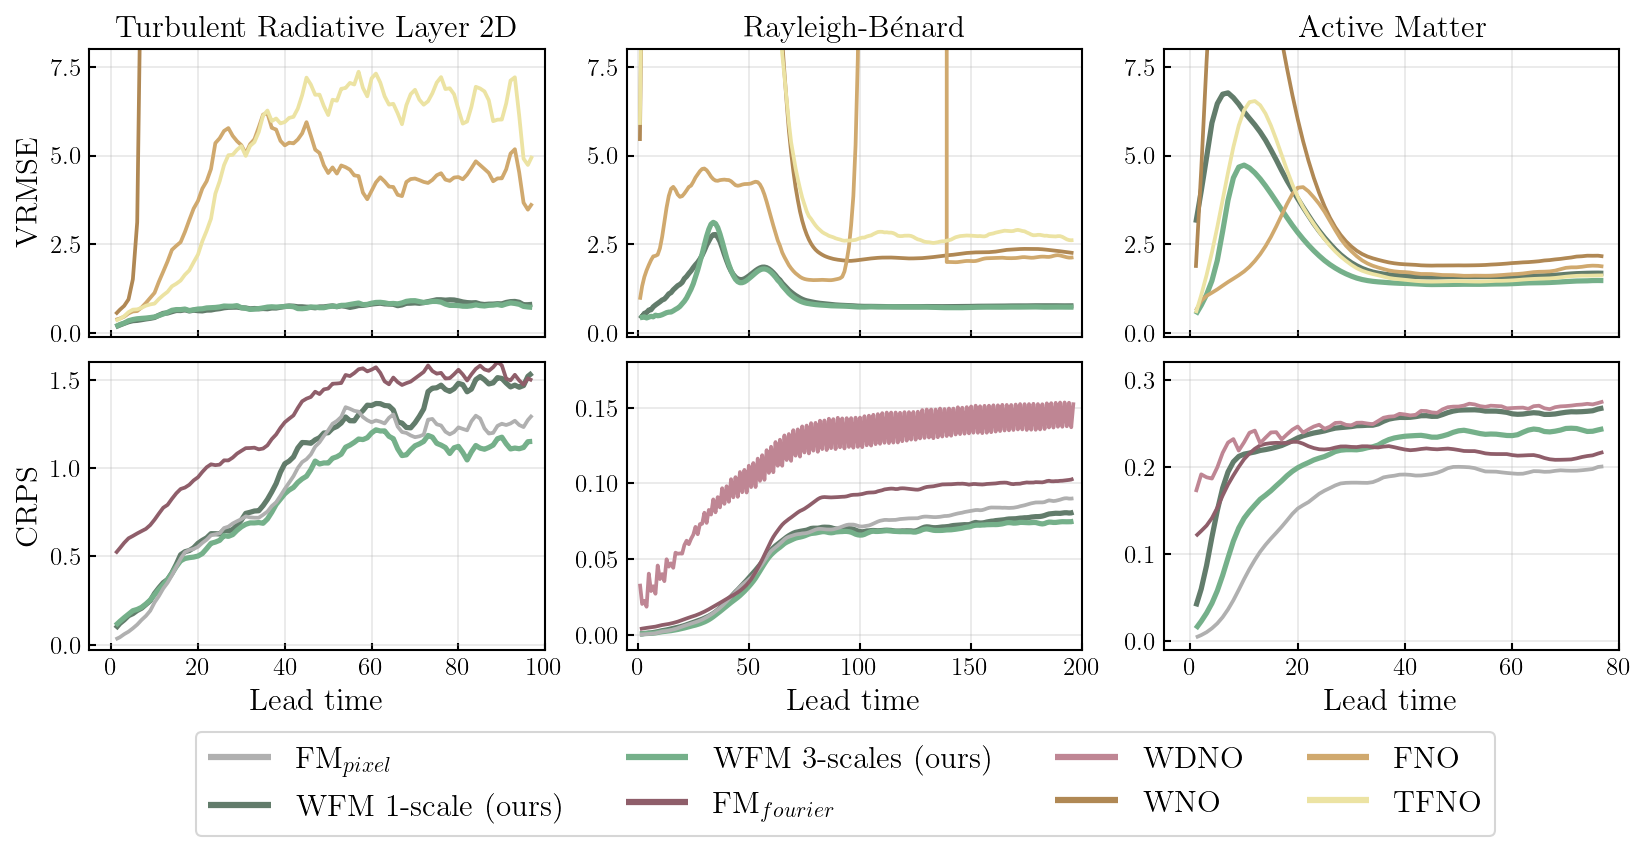

In [13]:
color_to_model = {v: k for k, v in palette.items()}

# Per-metric model filter
metric_models = {
    "VRMSE": [m for m in MODEL_REGISTRY if {"deterministic", "ours"} & set(MODEL_REGISTRY[m]["groups"])],
    "CRPS" : [m for m in MODEL_REGISTRY if "generative" in  MODEL_REGISTRY[m]["groups"]],
}

pde_metric_ylims = {
    'turbulent_radiative_layer_2D': {
        "VRMSE": (-0.1, 8.0),
        "CRPS":  (-0.03, 1.6),
    },
    'rayleigh_benard': {
        "VRMSE": (-0.1, 8.0),
        "CRPS":  (-0.01, 0.18),
    },
    'active_matter': {
        "VRMSE": (-0.1, 8.0),
        "CRPS":  (-0.01, 0.32),
    },
}

metrics     = ["VRMSE", "CRPS"]
metric_cols = {"VRMSE": "vrmse", "CRPS": "crps"}
n_metrics   = len(metrics)

fig2, axs2 = plt.subplots(
    n_metrics, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_metrics),
    sharex="col",
    sharey=False,
)

raw_h, raw_l = None, None
all_key_to_handle = {}

for col, pde in enumerate(PDEs):
    for row, metric in enumerate(metrics):
        ax = axs2[row, col]

        table = stats_df[
            (stats_df["pde"]   == pde) &
            (stats_df["model"].isin(metric_models[metric]))
        ]

        sns.lineplot(
            table, x="step", y=metric_cols[metric],
            hue="model", style="model",        
            dashes=dashes, estimator=aggregate, errorbar=None,
            palette=palette, ax=ax, linewidth=1.0,
            alpha=1.0,
        )

        for line in ax.get_lines():
            hex_color = mcolors.to_hex(line.get_color())
            model = color_to_model.get(hex_color)
            if model and model in linewidths:
                line.set_linewidth(linewidths[model])

        # Accumulate handles from every panel
        h, l = ax.get_legend_handles_labels()
        for key, handle in zip(l, h):
            if key not in all_key_to_handle:      
                all_key_to_handle[key] = handle

        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ylo, yhi = pde_metric_ylims[pde][metric]
        ax.set_ylim(ylo, yhi)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
        ax.set_xlabel("Lead time" if row == n_metrics - 1 else "", fontsize=15)
        if col == 0:
            ax.set_ylabel(metric, fontsize=15)
        else:
            ax.set_ylabel("")
        ax.tick_params(labelleft=True, labelsize=12)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

fig2.align_labels()
fig2.tight_layout(pad=0.8)
fig2.subplots_adjust(bottom=0.22, left=0.08, right=0.93)

ordered_keys    = legend_order(list(all_key_to_handle.keys()))
ordered_handles = [all_key_to_handle[k] for k in ordered_keys]
ordered_labels  = [labels.get(k, k)     for k in ordered_keys]

legend = fig2.legend(
    ordered_handles, ordered_labels,
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=True, fontsize=15,
)
for handle in legend.legend_handles:
    handle.set_linewidth(3.0)

# Save as PDF
#plt.savefig(f"{PROJECT_ROOT}/figures/fig2_appendix.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# APPENDIX Figure: SPLIT VRMSE & CRPS 

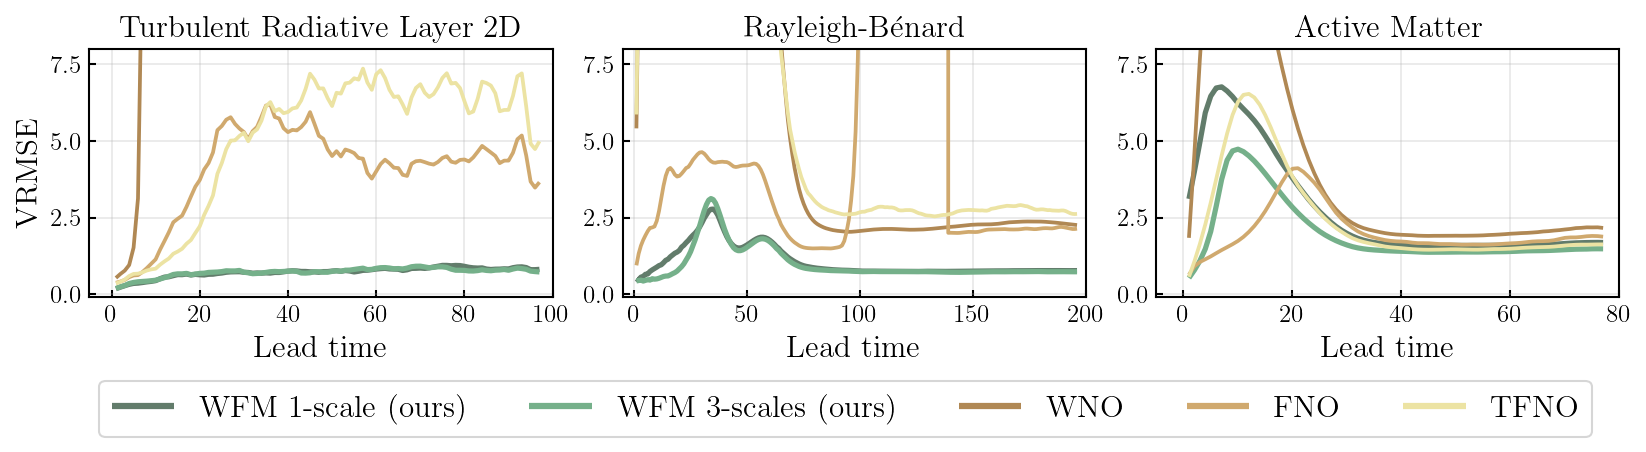

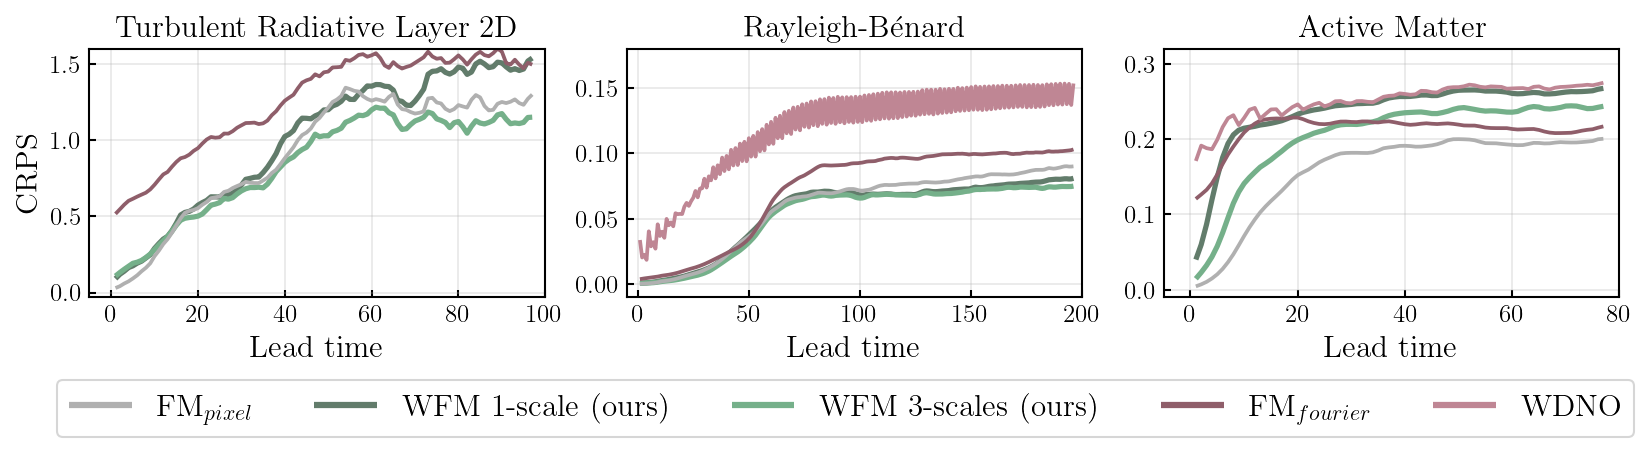

In [14]:
color_to_model = {v: k for k, v in palette.items()}

metric_models = {
    "VRMSE": [m for m in MODEL_REGISTRY if {"deterministic", "ours"} & set(MODEL_REGISTRY[m]["groups"])],
    "CRPS" : [m for m in MODEL_REGISTRY if "generative" in MODEL_REGISTRY[m]["groups"]],
}
pde_metric_ylims = {
    'turbulent_radiative_layer_2D': {"VRMSE": (-0.1, 8.0), "CRPS": (-0.03, 1.6)},
    'rayleigh_benard':              {"VRMSE": (-0.1, 8.0), "CRPS": (-0.01, 0.18)},
    'active_matter':                {"VRMSE": (-0.1, 8.0), "CRPS": (-0.01, 0.32)},
}
metric_cols = {"VRMSE": "vrmse", "CRPS": "crps"}

for metric in ["VRMSE", "CRPS"]:
    fig, axs = plt.subplots(
        1, n_pdes,
        figsize=(TEXT_WIDTH, ROW_HEIGHT),
        sharex=False, sharey=False,
    )
    key_to_handle = {}

    for col, pde in enumerate(PDEs):
        ax = axs[col]
        table = stats_df[
            (stats_df["pde"]   == pde) &
            (stats_df["model"].isin(metric_models[metric]))
        ]
        sns.lineplot(
            table, x="step", y=metric_cols[metric],
            hue="model", style="model",
            dashes=dashes, estimator=aggregate, errorbar=None,
            palette=palette, ax=ax, linewidth=1.0, alpha=1.0,
        )
        for line in ax.get_lines():
            model = color_to_model.get(mcolors.to_hex(line.get_color()))
            if model and model in linewidths:
                line.set_linewidth(linewidths[model])

        h, l = ax.get_legend_handles_labels()
        for key, handle in zip(l, h):
            if key not in key_to_handle:
                key_to_handle[key] = handle
        ax.get_legend().remove()

        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ax.set_ylim(*pde_metric_ylims[pde][metric])
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
        ax.set_xlabel("Lead time", fontsize=15)
        ax.set_ylabel(metric if col == 0 else "", fontsize=15)
        ax.tick_params(labelleft=True, labelsize=12)
        ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

    ordered_keys    = legend_order(list(key_to_handle.keys()))
    ordered_handles = [key_to_handle[k] for k in ordered_keys]
    ordered_labels  = [labels.get(k, k) for k in ordered_keys]

    fig.align_labels()
    fig.tight_layout(pad=0.8)
    fig.subplots_adjust(bottom=0.28, left=0.08, right=0.93)

    legend = fig.legend(
        ordered_handles, ordered_labels,
        loc="lower center", ncol=6,
        bbox_to_anchor=(0.5, -0.09),
        frameon=True, fontsize=15,
    )
    for handle in legend.legend_handles:
        handle.set_linewidth(3.0)

    fname = "fig2A_appendix.pdf" if metric == "VRMSE" else "fig2B_appendix.pdf"
    #fig.savefig(f"{PROJECT_ROOT}/figures/{fname}", dpi=400, bbox_inches="tight", transparent=False)
    plt.show()